# Glacier Album: EIC Data Exploration

Issue #8. This notebook collects the ice-related visualizations in NASA's [Earth Information Center (EIC) gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/), measures how their frames change over time, and helps us decide which ones become tracks on the glacier album.

Run it with `npm run notebook`. Downloads are cached in `notebooks/.cache/` (git-ignored), so only the first run is slow.

Steps:

1. Crawl the EIC gallery through the [SVS API](https://svs.gsfc.nasa.gov/help/#apis).
2. Find the ice-related visualizations.
3. List the media each one offers.
4. Decode the videos frame by frame and measure the ice in every frame.
5. Compare the candidates to pick tracks.

In [1]:
import json
import re
import urllib.request
from pathlib import Path

import av
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.dpi"] = 72

API = "https://svs.gsfc.nasa.gov/api/"
EIC_GALLERY_ID = 40467
CACHE = Path(".cache")
(CACHE / "api").mkdir(parents=True, exist_ok=True)
(CACHE / "media").mkdir(parents=True, exist_ok=True)


def fetch_json(page_id):
    """Fetch one SVS page from the API, cached on disk."""
    path = CACHE / "api" / f"{page_id}.json"
    if not path.exists():
        with urllib.request.urlopen(f"{API}{page_id}", timeout=60) as r:
            path.write_bytes(r.read())
    return json.loads(path.read_text())


def fetch_file(url):
    """Download a media file once and return its local path."""
    url = url.replace("http://", "https://")
    path = CACHE / "media" / url.split("/")[-1]
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

## 1. Crawl the EIC gallery

The EIC gallery is a tree: dashboards and video collections are sub-galleries, and the leaves are visualization pages. We walk the whole tree and keep every leaf with the dashboard it sits in.

In [2]:
def crawl(gallery_id):
    pages, seen = {}, set()

    def walk(page_id, path):
        if page_id in seen:
            return
        seen.add(page_id)
        page = fetch_json(page_id)
        if page.get("page_type") != "Gallery":
            pages[page_id] = {"id": page_id, "title": page["title"], "type": page.get("page_type"),
                              "dashboard": path[-1], "release": page.get("release_date", "")[:10]}
            return
        for group in page.get("media_groups", []):
            for item in group.get("items", []):
                inst = item.get("instance") or {}
                if item["type"] in ("gallery_page", "details_page") and inst.get("id"):
                    walk(inst["id"], path + [page["title"]])

    walk(gallery_id, [])
    return pd.DataFrame(pages.values())


eic = crawl(EIC_GALLERY_ID)
print(f"{len(eic)} pages in the EIC gallery")
eic.groupby("dashboard").size().sort_values(ascending=False)

79 pages in the EIC gallery


dashboard
Earth Information Center (EIC)      15
NASA and Agriculture Video          14
Daily Visualizations                10
Climate Vital Signs Dashboard        9
Earth Now Dashboard                  9
Greenhouse Gases Dashboard           7
NASA and Hurricanes                  7
Air Quality Dashboard                3
Wildland Fires Dashboard             3
Carbon Dioxide Sources and Sinks     2
dtype: int64

## 2. Find the ice-related visualizations

We search each page's title and SVS keywords for ice terms. Descriptions are left out: they mention snow or melting in passing on pages about temperature, rain or hurricanes.

In [3]:
ICE_TERMS = r"\b(ice|glacier|greenland|antarctic|arctic|snow|sea level|cryo|polar|melt)"


def ice_text(page_id):
    page = fetch_json(page_id)
    keywords = " ".join(k["title"] if isinstance(k, dict) else str(k) for k in page.get("keywords", []))
    return f"{page['title']} {keywords}"


eic["ice_hits"] = eic["id"].map(lambda i: sorted(set(m.lower() for m in re.findall(ICE_TERMS, ice_text(i), re.I))))
candidates = eic[eic["ice_hits"].str.len() > 0].sort_values("dashboard").reset_index(drop=True)
candidates["url"] = "https://svs.gsfc.nasa.gov/" + candidates["id"].astype(str) + "/"
candidates[["id", "title", "dashboard", "release", "ice_hits", "url"]]

,id,title,dashboard,release,ice_hits,url
0,5099,"Daily Polar Sea Ice, Two Year History",Climate Vital Signs Dashboard,2023-05-01,"[cryo, ice, polar]",https://svs.gsfc.nasa.gov/5099/
1,5207,Global Temperature Anomalies from 1880 to 2023,Climate Vital Signs Dashboard,2024-01-12,[sea level],https://svs.gsfc.nasa.gov/5207/
2,5382,Arctic Sea Ice Minimum 2024,Climate Vital Signs Dashboard,2024-09-24,"[arctic, cryo, ice, melt]",https://svs.gsfc.nasa.gov/5382/
3,5235,Sea Level Through a Porthole (2023),Climate Vital Signs Dashboard,2024-03-21,[sea level],https://svs.gsfc.nasa.gov/5235/
4,5046,"Daily Arctic Sea Ice, By Year",Daily Visualizations,2022-11-28,"[arctic, cryo, ice, polar]",https://svs.gsfc.nasa.gov/5046/
5,5064,"Daily Antarctic Sea Ice, By Year",Daily Visualizations,2023-01-17,"[antarctic, cryo, ice, polar]",https://svs.gsfc.nasa.gov/5064/
6,14713,Building Coastal Resilience with NASA Data,Earth Information Center (EIC),2025-01-07,[sea level],https://svs.gsfc.nasa.gov/14713/


Note: the EIC gallery has no visualization of land glaciers or ice sheet mass loss on its own. Its ice content is **sea ice** (Arctic and Antarctic) and **sea level**, which melting glaciers and ice sheets feed. The ice sheets of Greenland and Antarctica do appear, as white landmasses, in the sea ice globes. If the album needs real glacier data, other NASA visualizations outside the EIC can be added later.

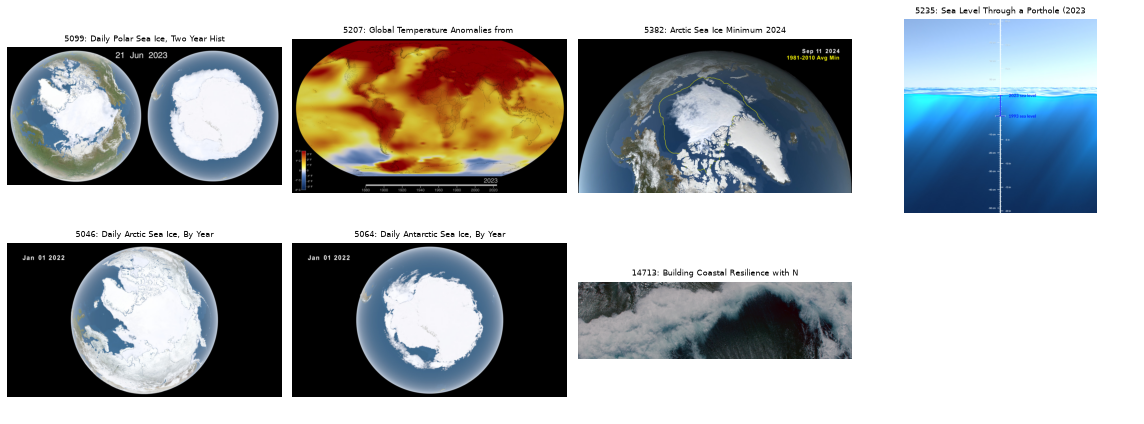

In [4]:
def preview(page_id):
    page = fetch_json(page_id)
    image = page.get("main_image") or {}
    return image.get("url")


fig, axes = plt.subplots(2, (len(candidates) + 1) // 2, figsize=(16, 6))
for ax, (_, row) in zip(axes.flat, candidates.iterrows()):
    url = preview(row["id"])
    if url:
        ax.imshow(Image.open(fetch_file(url)))
    ax.set_title(f"{row['id']}: {row['title'][:34]}", fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(candidates):]:
    ax.axis("off")
plt.tight_layout()

## 3. Media each candidate offers

SVS publishes frame sequences as EXR files (about 10 MB per frame, one frame per day), which are heavy to process. The same frames are also published as MP4 videos, so we decode the videos instead. Each video frame is one day of data.

In [5]:
def media(page_id):
    rows = []
    for group in fetch_json(page_id)["media_groups"]:
        for item in group.get("items", []):
            inst = item.get("instance") or {}
            if item["type"] == "media" and inst.get("media_type") in ("Movie", "Frames"):
                rows.append({"page": page_id, "kind": inst["media_type"], "file": inst["filename"],
                             "size": f"{inst.get('width')}x{inst.get('height')}", "url": inst["url"]})
    return rows


catalog = pd.DataFrame([r for i in candidates["id"] for r in media(i)])
catalog[catalog["file"].str.endswith(".mp4")][["page", "file", "size"]]

,page,file,size
0,5099,polar_sea_ice_sxs_w_date_2048p30_h265.mp4,4096x2048
3,5099,polar_sea_ice_sxs_no_date_2048p30_h265.mp4,4096x2048
6,5207,2023GISTEMP_Map_HD.mp4,1920x1080
8,5207,2023GISTEMP_Map.mp4,3840x2160
9,5207,2023GISTEMP_Map_SOS.mp4,4096x2048
10,5207,GISTEMP_1880-2023_vert.mp4,1080x1920
11,5382,sea_ice_2024_min_1080p60.mp4,1920x1080
13,5382,sea_ice_2024_min_2160p60.mp4,3840x2160
15,5382,sea_ice_2024_vert_1920p60.mp4,1080x1920
17,5235,seaLevelWaveTankComp_noWW_3-5-5-2024a_2160p30.mp4,2160x2160


## 4. Measure the ice in every frame

We pick the videos without date overlays so text doesn't count as ice. Each frame is scaled down to 480 px wide, then:

- **ice**: share of the globe covered by white pixels (bright and unsaturated)
- **ocean**: share of the globe covered by blue pixels
- **brightness**: mean brightness of the globe
- **water**: height of the water line, as a share of the frame height (only meaningful for the sea level porthole)

These are visual measures, not scientific ones. "Ice" also counts snow on land and the permanent ice sheets of Greenland and Antarctica, which never melt away in these videos and form a steady baseline. They show how the picture changes, which is what we turn into sound.

In [6]:
VIDEOS = {
    "Arctic 2021": (5046, "arctic_sea_ice_2021.mp4"),
    "Arctic 2022": (5046, "arctic_sea_ice_2022.mp4"),
    "Arctic 2023": (5046, "arctic_sea_ice_2023_no_dates.mp4"),
    "Arctic 2024": (5046, "arctic_sea_ice_2024_no_dates.mp4"),
    "Antarctic 2021": (5064, "antarctic_sea_ice_2021.mp4"),
    "Antarctic 2022": (5064, "antarctic_sea_ice_2022.mp4"),
    "Antarctic 2023": (5064, "antarctic_sea_ice_2023_no_dates.mp4"),
    "Antarctic 2024": (5064, "antarctic_sea_ice_2024_no_dates.mp4"),
    "Polar two years": (5099, "polar_sea_ice_sxs_no_date_2048p30_h265.mp4"),
    "Arctic minimum 2024": (5382, "sea_ice_2024_min_1080p60.mp4"),
    "Sea level porthole": (5235, "seaLevelWaveTank_noWW_3-5-2024a_wavetank.mp4"),
}


def video_url(page_id, filename):
    match = catalog[(catalog["page"] == page_id) & (catalog["file"] == filename)]
    return match["url"].iloc[0]


def measure(rgb):
    rgb = rgb.astype(np.int16)
    lo, hi = rgb.min(axis=2), rgb.max(axis=2)
    globe = rgb.sum(axis=2) > 40
    ice = (lo > 190) & (hi - lo < 35)
    ocean = (rgb[..., 2] > rgb[..., 0] + 30) & (rgb[..., 2] > 80)
    n = max(globe.sum(), 1)
    deep = (rgb[..., 0] < 110) & (rgb[..., 2] > 120) & (rgb[..., 2] > rgb[..., 0] + 60)
    wet_rows = np.flatnonzero(deep.mean(axis=1) > 0.5)
    water = 1 - wet_rows[0] / len(rgb) if len(wet_rows) else 0.0
    return ice[globe].sum() / n, ocean[globe].sum() / n, hi[globe].mean() / 255, water


def analyze(name, page_id, filename, width=480):
    path = fetch_file(video_url(page_id, filename))
    rows, samples = [], []
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        height = round(width * stream.codec_context.height / stream.codec_context.width / 2) * 2
        for i, frame in enumerate(container.decode(stream)):
            rgb = frame.to_ndarray(width=width, height=height, format="rgb24")
            ice, ocean, brightness, water = measure(rgb)
            rows.append({"video": name, "frame": i, "ice": ice, "ocean": ocean,
                         "brightness": brightness, "water": water})
            samples.append(rgb)
    picks = np.linspace(0, len(samples) - 1, 6).astype(int)
    return pd.DataFrame(rows), [samples[i] for i in picks], picks


frames, sheets = [], {}
for name, (page_id, filename) in VIDEOS.items():
    df, thumbs, picks = analyze(name, page_id, filename)
    frames.append(df)
    sheets[name] = (thumbs, picks)
    print(f"{name}: {len(df)} frames")
frames = pd.concat(frames, ignore_index=True)

Arctic 2021: 365 frames


Arctic 2022: 365 frames


Arctic 2023: 368 frames


Arctic 2024: 366 frames


Antarctic 2021: 365 frames


Antarctic 2022: 365 frames


Antarctic 2023: 367 frames


Antarctic 2024: 366 frames


Polar two years: 730 frames


Arctic minimum 2024: 3260 frames


Sea level porthole: 1500 frames


### Contact sheets

Six evenly spaced frames from each video, to check what the measures are looking at.

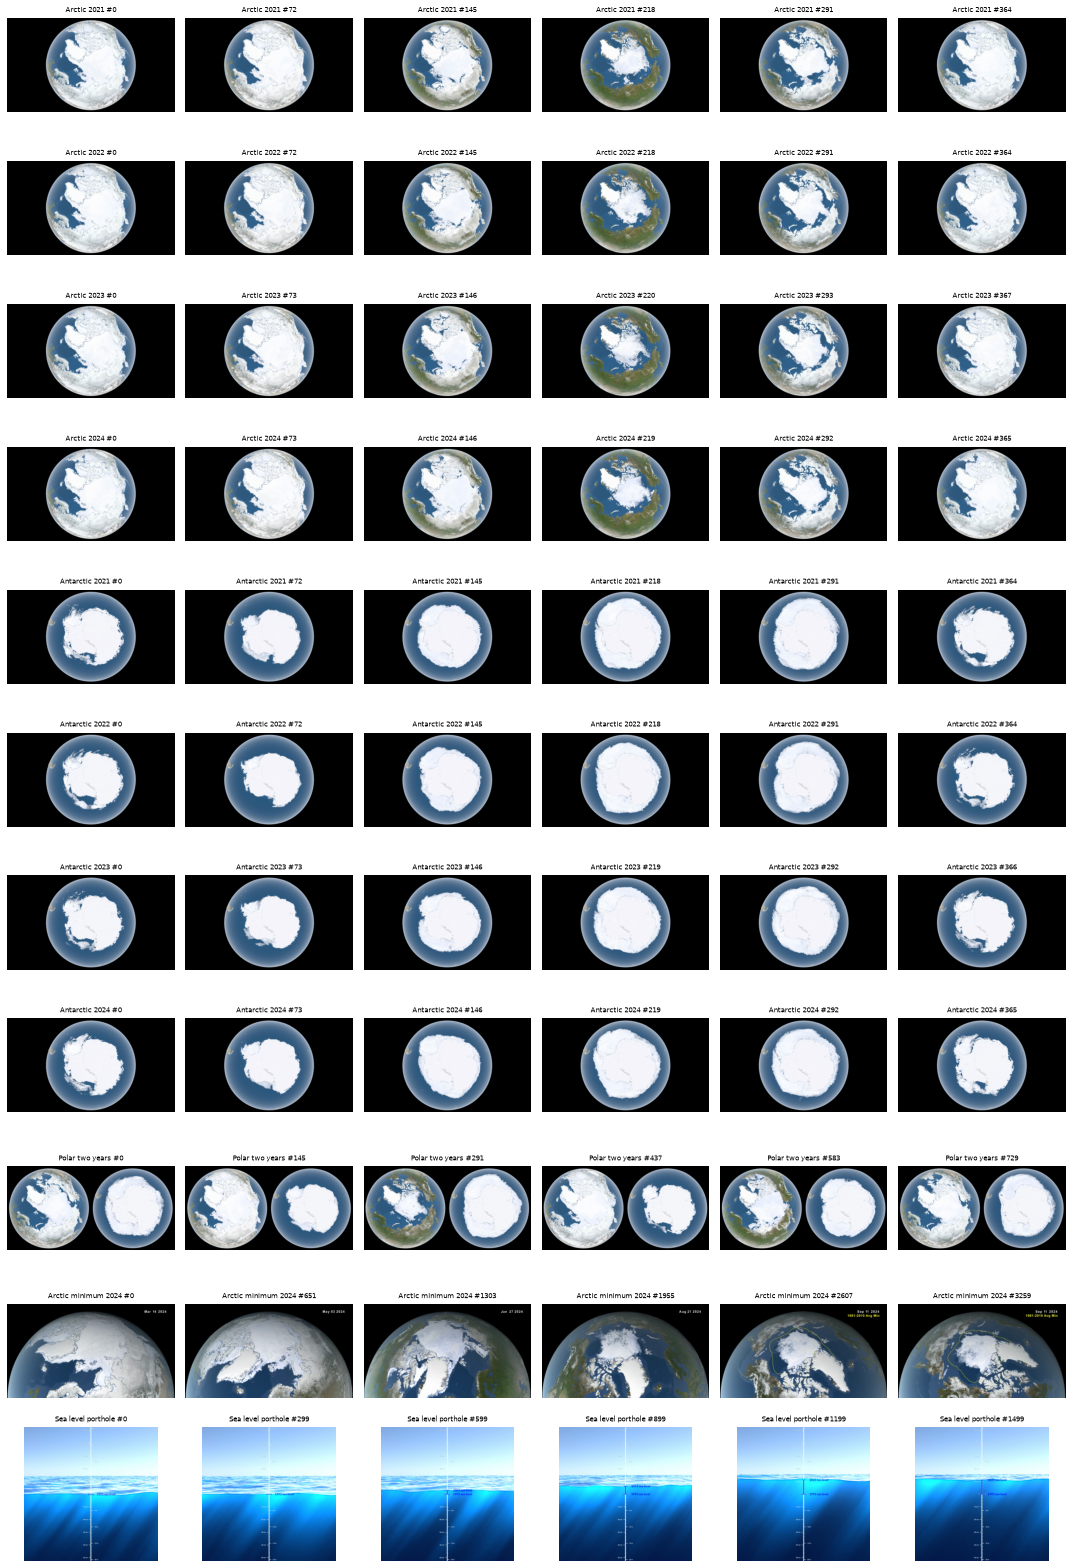

In [7]:
fig, axes = plt.subplots(len(sheets), 6, figsize=(15, 2 * len(sheets)))
for row, (name, (thumbs, picks)) in zip(axes, sheets.items()):
    for ax, img, i in zip(row, thumbs, picks):
        ax.imshow(img)
        ax.set_title(f"{name} #{i}", fontsize=7)
        ax.axis("off")
plt.tight_layout()

### Ice over time

One line per video. For the yearly Arctic and Antarctic videos, the x axis is the day of the year.

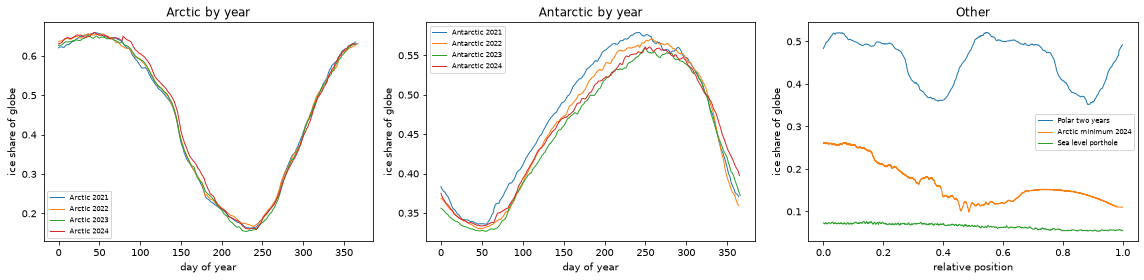

In [8]:
groups = {
    "Arctic by year": [n for n in VIDEOS if n.startswith("Arctic 20")],
    "Antarctic by year": [n for n in VIDEOS if n.startswith("Antarctic 20")],
    "Other": [n for n in VIDEOS if not re.match(r"(Arctic|Antarctic) 20", n)],
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (title, names) in zip(axes, groups.items()):
    for name in names:
        series = frames[frames["video"] == name]
        x = series["frame"] / series["frame"].max() if title == "Other" else series["frame"]
        ax.plot(x, series["ice"], label=name, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("relative position" if title == "Other" else "day of year")
    ax.set_ylabel("ice share of globe")
    ax.legend(fontsize=7)
plt.tight_layout()

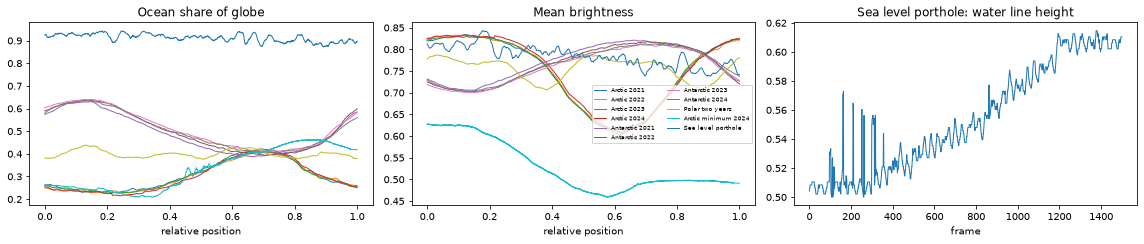

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for name in VIDEOS:
    series = frames[frames["video"] == name]
    x = series["frame"] / series["frame"].max()
    axes[0].plot(x, series["ocean"], linewidth=1, label=name)
    axes[1].plot(x, series["brightness"], linewidth=1, label=name)
porthole = frames[frames["video"] == "Sea level porthole"]
axes[2].plot(porthole["frame"], porthole["water"], linewidth=1)
axes[0].set_title("Ocean share of globe")
axes[1].set_title("Mean brightness")
axes[2].set_title("Sea level porthole: water line height")
axes[0].set_xlabel("relative position")
axes[1].set_xlabel("relative position")
axes[2].set_xlabel("frame")
axes[1].legend(fontsize=6, ncol=2)
plt.tight_layout()

## 5. Compare the candidates

How much each video changes, and how fast. A track needs enough movement to hear.

- **range**: max ice share minus min ice share
- **step**: mean absolute change per frame (how lively the sound would be)

In [10]:
summary = frames.groupby("video", sort=False).agg(
    frames=("frame", "size"),
    ice_min=("ice", "min"),
    ice_max=("ice", "max"),
    ice_mean=("ice", "mean"),
    step=("ice", lambda s: s.diff().abs().mean()),
)
summary["range"] = summary["ice_max"] - summary["ice_min"]
summary.insert(0, "page", [VIDEOS[n][0] for n in summary.index])
summary.round(4).sort_values("range", ascending=False)

,page,frames,ice_min,ice_max,ice_mean,step,range
video,,,,,,,
Arctic 2024,5046,366,0.1605,0.6597,0.4495,0.0029,0.4992
Arctic 2023,5046,368,0.1542,0.6520,0.4424,0.0028,0.4978
Arctic 2021,5046,365,0.1624,0.6584,0.4429,0.0028,0.4960
Arctic 2022,5046,365,0.1670,0.6557,0.4450,0.0028,0.4887
Antarctic 2021,5064,365,0.3357,0.5792,0.4706,0.0015,0.2435
Antarctic 2022,5064,365,0.3299,0.5706,0.4599,0.0014,0.2407
Antarctic 2023,5064,367,0.3265,0.5596,0.4505,0.0013,0.2331
Antarctic 2024,5064,366,0.3335,0.5607,0.4583,0.0013,0.2272
Polar two years,5099,730,0.3517,0.5213,0.4541,0.0011,0.1696


## Picking tracks

Questions to settle before building the album:

- **Story order**: which videos tell the story best in sequence? For example: Arctic year by year (2021 to 2024), then the 2024 Arctic minimum, then the Antarctic, ending with sea level rise.
- **Enough change**: drop videos whose range is too small to hear.
- **Data to sound**: which measure drives which sound? Ice share could drive pitch or volume, ocean share a drone, brightness the timbre.
- **Track length**: yearly videos have about 365 frames (one per day); at 30 fps that is about 12 seconds. Decide the playback speed per track.